# Calibration of the preliminary sea ice mask

The preliminary sea ice mask is designed with the assumption that the cloud and land masks are correct. For the clear sky water regions, the assumption is that the image may be bimodal or unimodal, and we want to create a mask where the ice floes are 100% in the sea ice region and the open water samples are 100% in the open water section. Other than that, there can be a fairly broad region of good performance (for our purposes at least).

For now the binary water masks are read from file, while the images are read from the DataLoader. 

In [1]:
using Pkg
Pkg.activate("calval")
Pkg.update("IceFloeTracker")

  Activating project at `~/Documents/research/calval_tgrs/notebooks/calval`
    Updating registry at `~/.julia/registries/General.toml`
    Updating git-repo `https://github.com/WilhelmusLab/IceFloeTracker.jl.git`
    Updating `~/Documents/research/calval_tgrs/notebooks/calval/Project.toml`
  [04643c7a] ~ IceFloeTracker v1.0.0 `https://github.com/WilhelmusLab/IceFloeTracker.jl.git#main` ⇒ v1.0.0 `https://github.com/WilhelmusLab/IceFloeTracker.jl.git#main`
    Updating `~/Documents/research/calval_tgrs/notebooks/calval/Manifest.toml`
  [04643c7a] ~ IceFloeTracker v1.0.0 `https://github.com/WilhelmusLab/IceFloeTracker.jl.git#main` ⇒ v1.0.0 `https://github.com/WilhelmusLab/IceFloeTracker.jl.git#main`
Precompiling packages...
   5380.2 ms  ✓ IceFloeTracker
  1 dependency successfully precompiled in 8 seconds. 517 already precompiled.


# Getting the training and testing data
We use StatsBase sample to take a sample of 2/3 of the cases by number, stratifying by the presence sea ice floes larger than the minimum size. For training each algorithm component, we randomly select the Aqua or Terra scene for each image to avoid double-counting each date.

In [3]:
using Pkg
Pkg.activate("calval")
using IceFloeTracker
using Images
using DataFrames
using StatsBase
using Random

  Activating project at `~/Documents/research/manuscripts/cal-val_ice_floe_tracker/calval_tgrs/notebooks/calval`


In [32]:
dataset = Watkins2026Dataset(ref="main");

In [7]:
function validated_binary_water(case::Case)
    info(case).water_sample == 0 && return nothing
    (; case_number, region, date, satellite) = IceFloeTracker.Data._filename_parts(case)
    file = "data/validation_dataset/binary_water_samples/$(case_number)-$(region)-$(date)-$(satellite)-binary_water_samples.png"
    img = file |> case.loader |> load |> binarize_mask .|> Gray
    return img
end

validated_binary_water (generic function with 1 method)

In [34]:
# Group the data and take a random sample just on the Aqua data to get a set of case numbers
# stratified by the presence of sea ice floes larger than the minimum.
min_floe_size = 64
fraction = 2/3
seed = 20
rng = Random.default_rng(seed)
df = dataset.info
max_floe_sizes = Int64.(coalesce.(df[!, :maximum_floe_size], 0));
df[:, :ice_floes] = max_floe_sizes .> min_floe_size

gdf = groupby(df[df.satellite .== "aqua",:], :ice_floes)
train_data = []
test_data = []
for group in gdf
    n = round(Int64, fraction * nrow(group))
    idx_all = 1:nrow(group)
    train_idx = sample(rng, idx_all, n; replace=false, ordered=true)
    test_idx = [x for x ∈ idx_all if x ∉ train_idx]
    push!(train_data, group[train_idx, :])
    push!(test_data, group[test_idx, :])    
end
train_df = reduce(vcat, train_data)
test_df = reduce(vcat, test_data);
df[:, :train] = [x ∈ train_df.case_number for x in df.case_number]
satellite = sample(["aqua", "terra"], maximum(df.case_number); replace=true)
training = [x ∈ train_df.case_number for x in df.case_number]

# Now add a Boolean column to the dataset object, so we can filter on it.
dataset.info[:, :training_single] .= [
    (s == satellite[cn]) && training[cn] for (cn, s) in zip(dataset.info.case_number, dataset.info.satellite)
        ];
dataset.info[:, :testing_single] .= [
    (s == satellite[cn]) && !training[cn] for (cn, s) in zip(dataset.info.case_number, dataset.info.satellite)
        ];

# Add a column to indicate whether water samples have been generated yet
water_sample_files = readdir("../../ice_floe_validation_dataset/data/validation_dataset/binary_water_samples/")
water_sample_cases = parse.(Int64, first.(split.(water_sample_files, "-")))
dataset.info[:, :water_sample] = (x -> x ∈ water_sample_cases).(dataset.info.case_number)

# Now: get the training and testing data, single image per case.
train_cases = filter(c -> c.training_single, dataset) 
test_cases = filter(c -> c.testing_single, dataset);

In [36]:
length(train_cases)

129

In [37]:
floes = validated_binary_floes.(train_cases);

In [38]:
# Select only the cases which have defined water samples
cases = subset(train_cases, :water_sample => r -> r)

Dataset(GitHubLoader("https://github.com/danielmwatkins/ice-floe-validation-dataset/", "main", "/tmp/Watkins2026"), 18×31 DataFrame
 Row │        case_number  region               satellite  start_date  pass_ti ⋯
     │ Int64  Int64        String               String     Dates.Date  DateTim ⋯
─────┼──────────────────────────────────────────────────────────────────────────
   1 │     0            1  baffin_bay           terra      2022-09-11  2022-09 ⋯
   2 │    10            6  baffin_bay           terra      2022-05-30  2022-05
   3 │    13            7  baffin_bay           terra      2007-08-25  2007-08
   4 │    24           13  baffin_bay           aqua       2012-05-27  2012-05
   5 │    27           14  baffin_bay           terra      2022-07-06  2022-07 ⋯
   6 │    28           15  baffin_bay           terra      2021-08-04  2021-08
   7 │    56           29  barents_kara_seas    aqua       2014-07-08  2014-07
   8 │    62           32  barents_kara_seas    aqua       2014-05-0

In [64]:
cloud_algo = Watkins2025CloudMask()
fc_imgs = modis_falsecolor.(cases)
tc_imgs = modis_truecolor.(cases)
land_mask = modis_landmask.(cases) .|> x -> x .> 0
cloud_mask = cloud_algo.(fc_imgs);
water_samples = validated_binary_water.(cases)
binary_floes = validated_binary_floes.(cases);

In [41]:
land_mask = BitMatrix[]
coastal_buffer = BitMatrix[]
for img in lm_imgs
    cb, lm = create_landmask(img, strel_box((25,25)))
    push!(land_mask, lm)
    push!(coastal_buffer, cb)
end

# Truecolor images

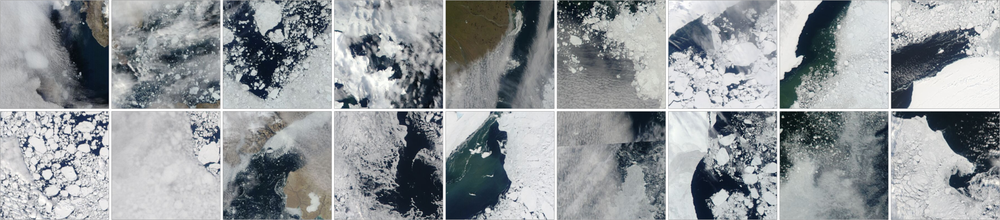

In [42]:
mosaicview(tc_imgs, nrow=2, npad=10, fillvalue=RGBA(0,0,0,0))

# Land masks

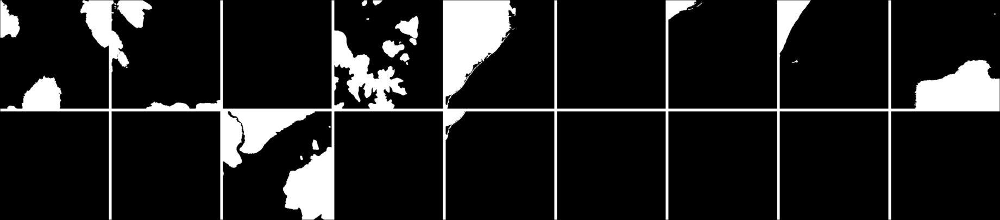

In [43]:
mosaicview(land_mask .|> x -> Gray.(x), nrow=2, npad=10, fillvalue=1)

# Cloud masks

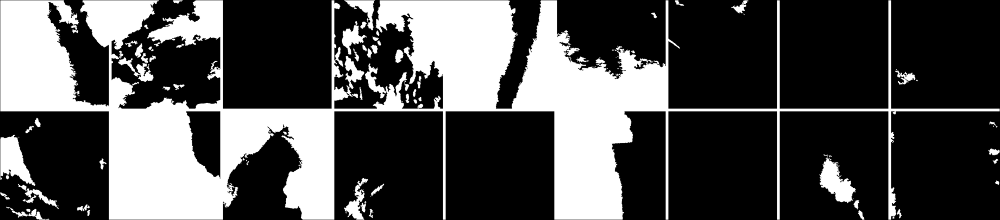

In [44]:
mosaicview(cloud_mask .|> x -> Gray.(x), nrow=2, npad=10, fillvalue=1)

# Default sea ice / water mask

In [46]:
ice_water_mask_ = IceDetectionBrightnessPeaksMODIS134(band_1_min=0.3)
binary_floes = validated_binary_floes.(cases)
tc_masked = apply_landmask.(apply_landmask.(tc_imgs, cloud_mask), land_mask)
test_iwm = ice_water_mask_.(tc_masked);

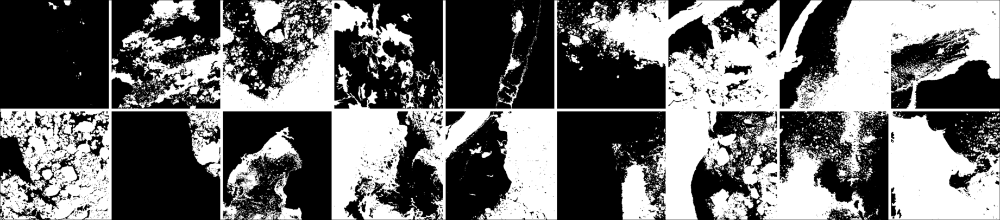

In [47]:
mosaicview(test_iwm .|> x -> Gray.(x), nrow=2, npad=10, fillvalue=1)

# Validated floes

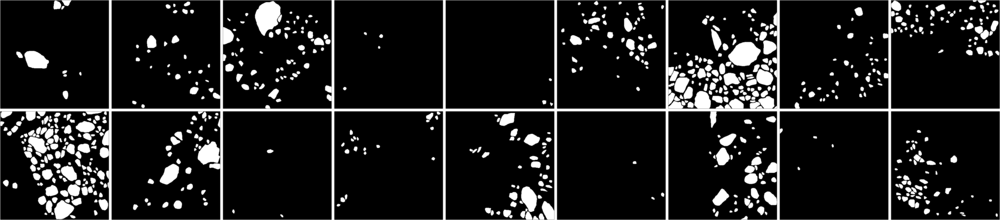

In [48]:
mosaicview([RGBA.(m) for m in binary_floes], nrow=2, npad=10, fillvalue=RGBA(0,0,0,0))

# Overlaying images and masks to check results

In [49]:
ground_truth_overlay = deepcopy(tc_imgs)
for idx in range(1, length(binary_floes) - 1)
    cm = cloud_mask[idx] .> 0
    lm = land_mask[idx] .> 0
    floes = binary_floes[idx] .> 0
    ice_water_mask = test_iwm[idx]
    water = water_samples[idx] .> 0
    ground_truth_overlay[idx][ .!ice_water_mask .&& water .&& .!cm ] .= RGBA(0, 0.1, 1, 1) # True positive for water
    ground_truth_overlay[idx][ice_water_mask .&& water .&& .!cm] .= RGBA(0.1, 1, 0, 1) # False negative for water
    ground_truth_overlay[idx][floes] .= RGBA(1, 1, 1, 1)
    ground_truth_overlay[idx][floes .&& water] .= RGB.(1, 0, 0)
end

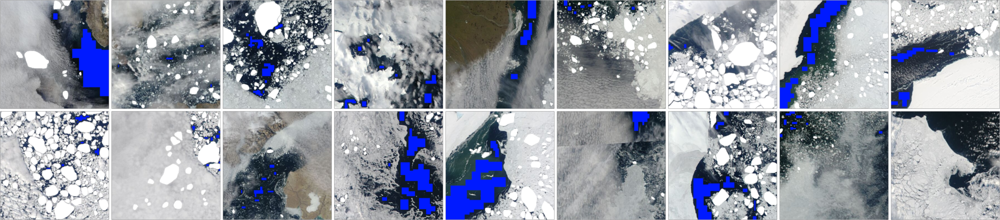

In [50]:
mosaicview(ground_truth_overlay, nrow=2, npad=10, fillvalue=RGBA(0,0,0,0))

In [51]:
overlays = []
for idx in collect(1:length(tc_imgs))
    
    cm_overlay = deepcopy(tc_imgs[idx])


    # Ice
    cm_overlay[test_iwm[idx]] .= RGBA(1,1,1,1)
    
    # Water
    w_idx = .!cloud_mask[idx] .&& .!test_iwm[idx]
    cm_overlay[w_idx] .= RGBA(0.2, 0.2, 1.)
    cm_overlay[coastal_buffer[idx]] .= RGBA(0.5,0.5,0.5,1)
    

    # conservative_threshold = (red.(tc_imgs[idx]) .> 0.1) .&& .! test_iwm[idx]
    # cm_overlay[conservative_threshold .> 0] .= RGBA(0.8, 0.8, 0.8, 1)
    
     # Clouds
    cm_overlay[cloud_mask[idx] .> 0] .= RGBA(0.8, 0.1, 0.7)

    # Land
    cm_overlay[land_mask[idx]] .= RGBA(0,0,0,1)
    
    outlines = binary_floes[idx] .- erode(binary_floes[idx], strel_box((5,5)))
    cm_overlay[outlines .> 0] .= RGBA(0, 1, 0, 1)
    tc_copy = deepcopy(tc_imgs[idx])
    tc_copy[outlines .> 0] .= RGBA(0, 1, 0, 1)
    
    outlines = water_samples[idx] .- erode(water_samples[idx])
    tc_copy[outlines .> 0] .= RGBA(0.7, 0.8, 1, 1)
    cm_overlay[outlines .> 0] .= RGBA(0.7, 0.8, 1, 1)
    
    # Left: water samples, validated ice floes
    push!(overlays, mosaicview(tc_copy, cm_overlay, nrow=2, npad=10, fillvalue=RGBA(0,0,0,0)))
end

# mosaicview(overlays, nrow=1)
nothing

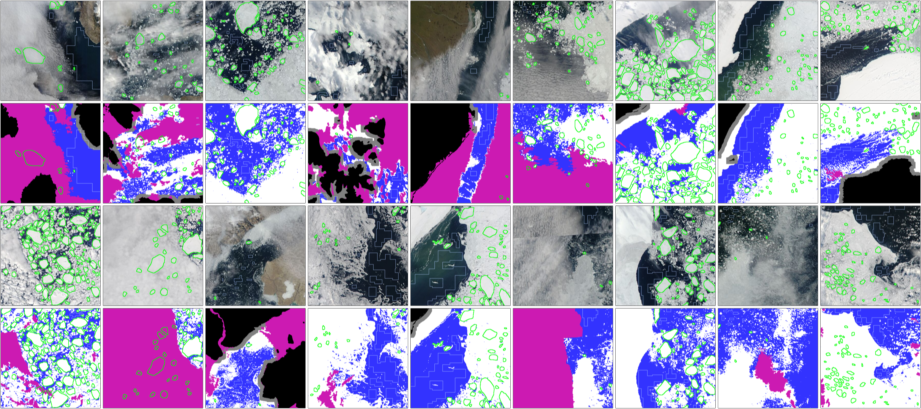

In [52]:
mosaicview(overlays..., nrow=2, npad=10, fillvalue=RGBA(0,0,0,0))

In [53]:
save("../figures/classification_results_init.png", mosaicview(overlays..., nrow=2, npad=5, fillvalue=RGBA(0,0,0,0)))

## Evaluating the results of the ice/water mask algorithm
The function only has one parameter: the minimum brightness. Hence, we need to see if there is any meaningful difference across a plausible range of minimum brightnesses. Focus range: 0.1 to 0.5.
First columns are the case number, satellite, and the minimum brightness threshold.

* TP: Predicts ice, is ice
* FP: Predicts ice, is water
* TN: Predicts water, is water
* FN: Predicts water, is ice
* Labeled floe pixels
* Water sample pixels

These will be pixel counts. 

Also compute:
* Ice fraction (labeled by algorithm)
* Water fraction (labeled by algorithm)
* Land fraction
* Cloud fraction
These are fractions of the image, and should add up to 1.



In [221]:
# Select only the cases which have defined water samples
cases = subset(train_cases, :water_sample => r -> r)

cloud_algo = Watkins2025CloudMask()
fc_imgs = modis_falsecolor.(cases)
tc_imgs = modis_truecolor.(cases)
land_masks = modis_landmask.(cases) .|> x -> x .> 0
cloud_masks = cloud_algo.(fc_imgs);
joined_masks = ((x, y) -> x .|| y).(land_masks, cloud_masks)
tc_masked = apply_landmask.(tc_imgs, joined_masks)
water_samples = validated_binary_water.(cases)
binary_floes = validated_binary_floes.(cases);

In [97]:
# First do this for all the cases with water samples, then we'll do it for the rest of the cases with ice.
df = DataFrame(
               case_number=Int64[],
               satellite=String[],               
               minimum_brightness=Float64[],
               floe_pixels=Int64[],
               water_sample_pixels=Int64[],
               land_pixels=Int64[],
               cloud_pixels=Int64[],
               ice_pixels=Int64[],
               water_pixels=Int64[],
               true_positive=Int64[],
               false_positive=Int64[],
               true_negative=Int64[],
               false_negative=Int64[],
               )
case_numbers = cases.info.case_number
satellites = cases.info.satellite
test_minima = 0.1:0.1:0.5

for idx in range(1, length(water_samples))

    land_pixels = sum(land_mask[idx] .> 0)
    cloud_pixels = sum(cloud_mask[idx] .> 0)
    water_truth = water_samples[idx] .> 0
    ice_truth = (binary_floes[idx] .> 0) .&& .!joined_masks[idx]
    ice_truth_pixels = sum(ice_truth)
    water_truth_pixels = sum(water_truth)
    n = prod(size(land_mask[idx]))
    
    for minval in test_minima
        classify_ice_water = IceDetectionBrightnessPeaksMODIS134(band_1_min=minval)
        ice_water_mask = classify_ice_water(tc_masked[idx])
        labeled_ice = sum(ice_water_mask)
        labeled_water = sum(.!ice_water_mask .&& .! joined_masks[idx])

        tp = sum(ice_water_mask .&& ice_truth)
        fp = sum(ice_water_mask .&& water_truth)
        tn = sum(.!ice_water_mask .&& water_truth)
        fn = sum(.!ice_water_mask .&& ice_truth)
        push!(df, 
            [case_numbers[idx],
             satellites[idx],
             minval,
             ice_truth_pixels,
             water_truth_pixels,
             land_pixels,
             cloud_pixels,
             labeled_ice, 
             labeled_water,
             tp,
             fp,
             tn,
             fn]
            )
    end
end

In [111]:
save("../data/ice_mask_calibration_water_samples.csv", df)

In [109]:
using Plots

18

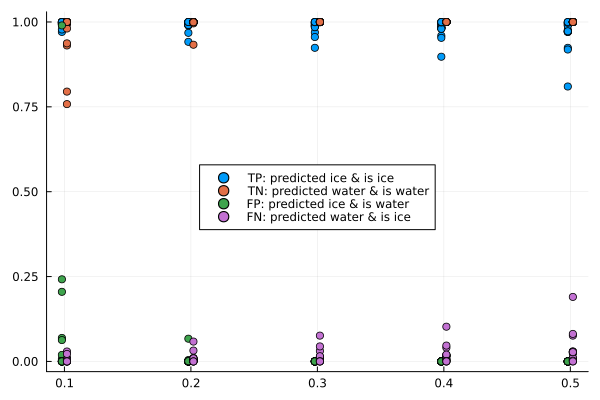

In [127]:
plot(legend=:legend)
scatter!(df[:, :minimum_brightness] .- 0.002, df[:, :true_positive] ./ df[:, :floe_pixels], label="TP: predicted ice & is ice")
scatter!(df[:, :minimum_brightness] .+ 0.002, df[:, :true_negative] ./ df[:, :water_sample_pixels], label="TN: predicted water & is water")
scatter!(df[:, :minimum_brightness] .- 0.002, df[:, :false_positive] ./ df[:, :water_sample_pixels], label="FP: predicted ice & is water")
scatter!(df[:, :minimum_brightness] .+ 0.002, df[:, :false_negative] ./ df[:, :floe_pixels], label="FN: predicted water & is ice")


* TP: Predicts ice, is ice
* FP: Predicts ice, is water
* TN: Predicts water, is water
* FN: Predicts water, is ice

## True positive rate for full set of training data + sensitivity

Based on the set of images where we have truth data for the water samples, we see that the algorithm classifies close to 100% of the labeled water masks correctly. There is more uncertainty in the classification of sea ice floes, likely due to edge effects, thin (dark) floes, and melt ponds. This is only using 18 cases -- more will come. In the next code block, we perform the same analysis but without comparison to water masks, so the only "truth" data is the labeled sea ice floes. This a larger, more robust dataset

In [110]:
cloud_algo = Watkins2025CloudMask()
fc_imgs = modis_falsecolor.(train_cases)
tc_imgs = modis_truecolor.(train_cases)
land_masks = modis_landmask.(train_cases) .|> x -> x .> 0
cloud_masks = cloud_algo.(fc_imgs);
joined_masks = ((x, y) -> x .|| y).(land_masks, cloud_masks)
tc_masked = apply_landmask.(tc_imgs, joined_masks)
binary_floes = validated_binary_floes.(train_cases);
print(nrow(train_cases.info))

129

In [138]:
length(land_masks)

129

In [183]:
# First do this for all the cases with water samples, then we'll do it for the rest of the cases with ice.
df2 = DataFrame(
               case_number=Int64[],
               satellite=String[],               
               minimum_brightness=Float64[],
               floe_pixels=Int64[],
               land_pixels=Int64[],
               cloud_pixels=Int64[],
               ice_pixels=Int64[],
               water_pixels=Int64[],
               true_positive=Int64[],
               false_negative=Int64[],
               )
case_numbers = train_cases.info.case_number
satellites = train_cases.info.satellite
test_minima = 0.1:0.1:0.5

for idx in range(1, length(land_masks))

    land_pixels = sum(land_masks[idx] .> 0)
    cloud_pixels = sum((cloud_masks[idx] .> 0) .&& .! (land_masks[idx] .> 0))
    if !isnothing(binary_floes[idx])
        ice_truth = (binary_floes[idx] .> 0) .&& .!joined_masks[idx]
        ice_truth_pixels = sum(ice_truth)
        n = prod(size(land_masks[idx]))
        for minval in test_minima
            # println(idx, " ", case_numbers[idx], " ", satellites[idx], " ", ice_truth_pixels)
            classify_ice_water = IceDetectionBrightnessPeaksMODIS134(band_1_min=minval)
            ice_water_mask = classify_ice_water(tc_masked[idx])
            labeled_ice = sum(ice_water_mask)
            labeled_water = sum(.!ice_water_mask .&& .! joined_masks[idx])
    
            tp = sum(ice_water_mask .&& ice_truth)
            fn = sum(.!ice_water_mask .&& ice_truth)
            push!(df2, 
                [case_numbers[idx],
                 satellites[idx],
                 minval,
                 ice_truth_pixels,
                 land_pixels,
                 cloud_pixels,
                 labeled_ice, 
                 labeled_water,
                 tp,
                 fn]
                )
        end
    end
end

In [151]:
length(binary_floes)

129

## Sensitivity of the estimated total sea ice fraction (ice pixels / ocean pixels) to minimum threshold

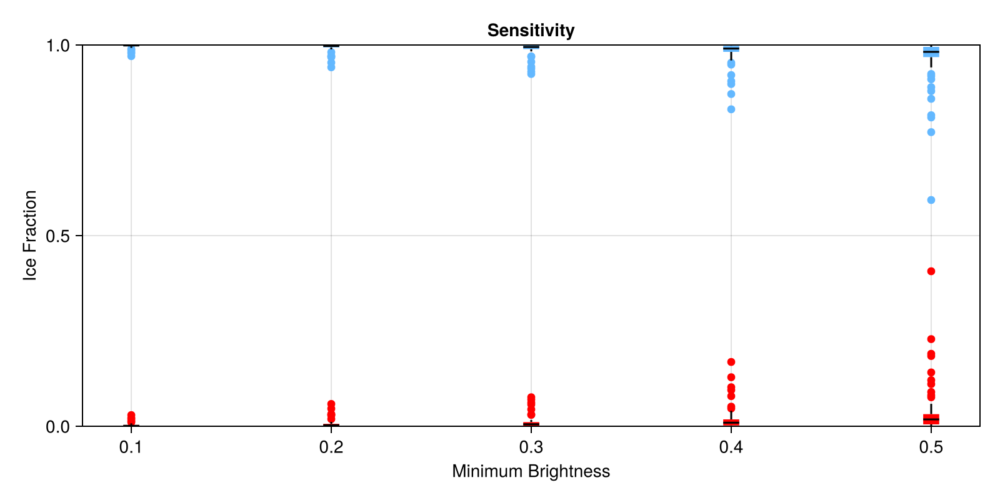

In [184]:
# How the sea ice fraction depends on the choice of threshold
fig = Figure(size=(800, 400))
ax = CairoMakie.Axis(fig[1, 1], ylabel="Ice Fraction", xlabel="Minimum Brightness", title="Sensitivity")
tpr = df2[:, :true_positive] ./ df2[:, :floe_pixels]
fnr = df2[:, :false_negative] ./ df2[:, :floe_pixels]

idx = .!isnan.(tpr)
CairoMakie.boxplot!(ax, df2[idx, :minimum_brightness], tpr[idx], width=0.01, color=:steelblue1)
CairoMakie.boxplot!(ax, df2[idx, :minimum_brightness], fnr[idx], width=0.01, color=:red1)
CairoMakie.ylims!(ax, (0, 1))
fig

In [167]:
using CairoMakie

In [173]:
maximum((n .- (df2[:, :land_pixels] .+ df2[:, :cloud_pixels])) ./ n)

1.0

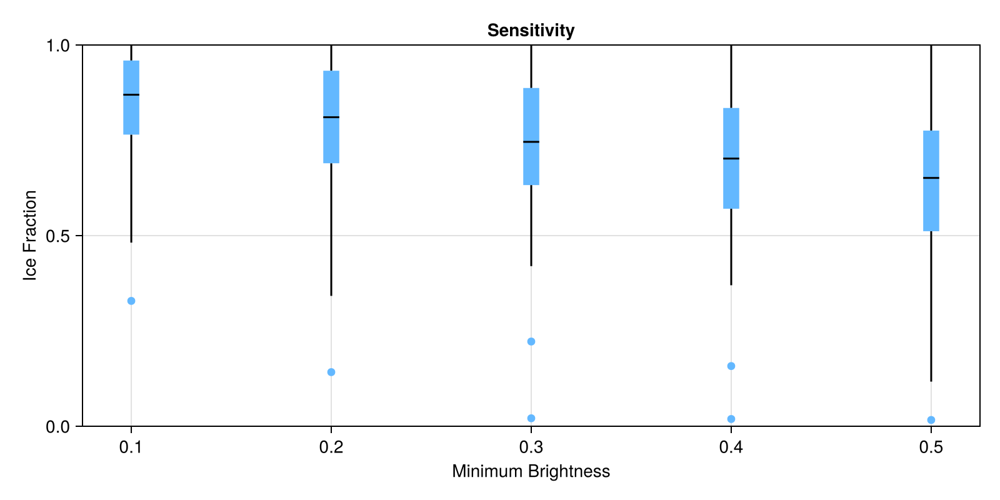

In [185]:
fig = Figure(size=(800, 400))
ax = CairoMakie.Axis(fig[1, 1], ylabel="Ice Fraction", xlabel="Minimum Brightness", title="Sensitivity")
ice_fraction = df2[:, :ice_pixels] ./ (n .- (df2[:, :land_pixels] .+ df2[:, :cloud_pixels]))
idx = .!isnan.(ice_fraction)
CairoMakie.boxplot!(ax, df2[idx, :minimum_brightness], ice_fraction[idx], width=0.01, color=:steelblue1)
CairoMakie.ylims!(ax, (0, 1))
fig

There is a clear decrease in ice fraction as the minimum brightness increases, as we'd expect.

In [190]:
df2[:, :ice_fraction] .= df2[:, :ice_pixels] ./ (n .- (df2[:, :land_pixels] .+ df2[:, :cloud_pixels]))
group_mean = combine(groupby(df2[idx, [:minimum_brightness, :ice_fraction]], :minimum_brightness), :ice_fraction => mean)

Row,minimum_brightness,ice_fraction_mean
,Float64,Float64
1,0.1,0.836111
2,0.2,0.784422
3,0.3,0.739217
4,0.4,0.693368
5,0.5,0.634845


# Testing against held-out data


In [224]:
cases = subset(test_cases, :water_sample => r -> r)

cloud_algo = Watkins2025CloudMask()
fc_imgs = modis_falsecolor.(cases)
tc_imgs = modis_truecolor.(cases)
land_masks = modis_landmask.(cases) .|> x -> x .> 0
cloud_masks = cloud_algo.(fc_imgs);
joined_masks = ((x, y) -> x .|| y).(land_masks, cloud_masks)
tc_masked = apply_landmask.(tc_imgs, joined_masks)
water_samples = validated_binary_water.(cases)
binary_floes = validated_binary_floes.(cases);

In [226]:
# First do this for all the cases with water samples, then we'll do it for the rest of the cases with ice.
df = DataFrame(
               case_number=Int64[],
               satellite=String[],               
               minimum_brightness=Float64[],
               floe_pixels=Int64[],
               water_sample_pixels=Int64[],
               land_pixels=Int64[],
               cloud_pixels=Int64[],
               ice_pixels=Int64[],
               water_pixels=Int64[],
               true_positive=Int64[],
               false_positive=Int64[],
               true_negative=Int64[],
               false_negative=Int64[],
               )
case_numbers = cases.info.case_number
satellites = cases.info.satellite
test_minima = [0.3]

for idx in range(1, length(water_samples))

    land_pixels = sum(land_masks[idx] .> 0)
    cloud_pixels = sum(cloud_masks[idx] .> 0)
    water_truth = water_samples[idx] .> 0
    if isnothing(binary_floes[idx])
        ice_truth = land_masks[idx] * 0
    else
        ice_truth = (binary_floes[idx] .> 0) .&& .!joined_masks[idx]
    end
    ice_truth_pixels = sum(ice_truth)
    water_truth_pixels = sum(water_truth)
    n = prod(size(land_mask[idx]))
    
    for minval in test_minima
        classify_ice_water = IceDetectionBrightnessPeaksMODIS134(band_1_min=minval)
        ice_water_mask = classify_ice_water(tc_masked[idx])
        labeled_ice = sum(ice_water_mask)
        labeled_water = sum(.!ice_water_mask .&& .! joined_masks[idx])

        tp = sum(ice_water_mask .&& ice_truth)
        fp = sum(ice_water_mask .&& water_truth)
        tn = sum(.!ice_water_mask .&& water_truth)
        fn = sum(.!ice_water_mask .&& ice_truth)
        push!(df, 
            [case_numbers[idx],
             satellites[idx],
             minval,
             ice_truth_pixels,
             water_truth_pixels,
             land_pixels,
             cloud_pixels,
             labeled_ice, 
             labeled_water,
             tp,
             fp,
             tn,
             fn]
            )
    end
end

In [228]:
sum(df.true_positive) / sum(df.floe_pixels)

0.9890240677069558

In [229]:
sum(df.true_negative) / sum(df.water_sample_pixels)

0.999756853686706

In [230]:
sum(df.false_positive) / sum(df.water_sample_pixels)

0.00024314631329402467

In [231]:
sum(df.false_negative) / sum(df.floe_pixels)

0.010975932293044168